## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Example A: 30 transportation-mode observations
modes = pd.Series(
    ["Taxi"] * 12 + ["Bus"] * 8 + ["Bike"] * 5 + ["Metro"] * 5,
    name="mode"
)

# Example B: 20 observed waiting times (in minutes)
waits = pd.Series(
    [3, 4, 4, 5, 5, 6, 6, 6, 7, 7,
     8, 8, 9, 10, 11, 12, 14, 18, 25, 41],
    name="wait_min"
)

print("Mode observations:", len(modes))
print("Waiting-time observations:", len(waits))
print("Waiting-time mean:", round(waits.mean(), 2))

Mode observations: 30
Waiting-time observations: 20
Waiting-time mean: 10.45


## Lab 1 — Categorical frequency counts 

**Question:** How often does each transportation mode appear?

**Tasks**
1. Use `value_counts()` to obtain the number of observations for each mode.
2. Confirm that the counts add up to the total sample size.
3. Draw a bar chart of the counts.
4. **Interpret:** Which mode is most common? Can you infer that it is the most common mode in Montréal? Why or why not?

mode
Taxi     12
Bus       8
Bike      5
Metro     5
Name: count, dtype: int64
Total: 30


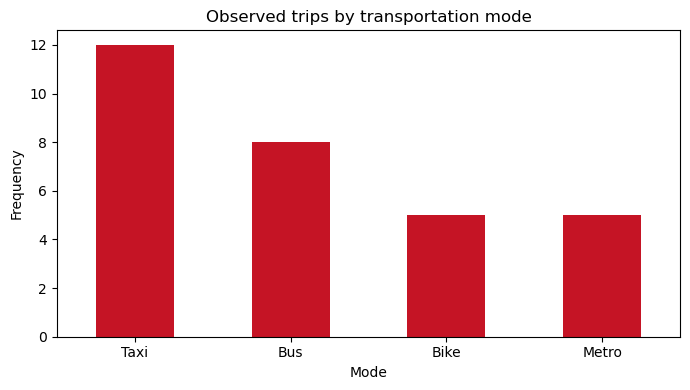

In [2]:
freq_mode = modes.value_counts()
total_count = freq_mode.sum()
print(freq_mode)
print("Total:", total_count)

ax = freq_mode.plot(kind="bar", color="#c51425", figsize=(7, 4))
ax.set_title("Observed trips by transportation mode")
ax.set_xlabel("Mode")
ax.set_ylabel("Frequency")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Lab 2 — Relative frequency and percentage 

**Question:** What share of the sample belongs to each mode?

**Tasks**
1. Calculate relative frequencies using `value_counts(normalize=True)`.
2. Convert them to percentages.
3. Combine count, proportion and percentage into one table.
4. Verify that the proportions sum to 1 (within rounding error).
5. **Interpret:** Explain why a count of 12 alone is less informative than 40% when comparing studies with different sample sizes.

In [3]:
relative_mode = modes.value_counts(normalize=True)
percentage_mode = relative_mode * 100

mode_summary = pd.DataFrame({
    "Frequency": freq_mode,
    "Proportion": relative_mode,
    "Percentage": percentage_mode
})
print(mode_summary.round(3))
print("Sum of proportions:", relative_mode.sum())

       Frequency  Proportion  Percentage
mode                                    
Taxi          12       0.400      40.000
Bus            8       0.267      26.667
Bike           5       0.167      16.667
Metro          5       0.167      16.667
Sum of proportions: 1.0


## Lab 3 — Cumulative frequency and service thresholds 

**Question:** How many waiting times are **at or below** a given threshold?

**Tasks**
1. For thresholds 5, 10, 15, 20, compute the count `waits <= threshold`.
2. Divide by 20 to calculate cumulative proportions and percentages.
3. Report how many observed waits are **above 20 minutes**.
4. **Interpret:** What percentage of these trips met a 10-minute service target?

**Important:** Cumulative frequencies require a meaningful ordering. Do not calculate a cumulative frequency for unordered modes such as Taxi, Bus, Bike and Metro.

In [4]:
thresholds = [5, 10, 15, 20]
cum_counts = [(waits <= t).sum() for t in thresholds]
cum_percent = [count / len(waits) * 100 for count in cum_counts]

threshold_table = pd.DataFrame({
    "Wait <= (min)": thresholds,
    "Cumulative count": cum_counts,
    "Cumulative %": cum_percent
})
print(threshold_table)
print("Waits > 20:", (waits > 20).sum())

   Wait <= (min)  Cumulative count  Cumulative %
0              5                 5          25.0
1             10                14          70.0
2             15                17          85.0
3             20                18          90.0
Waits > 20: 2


## Lab 4 — Build a grouped frequency table with `pd.cut()` 

**Question:** How does binning summarize continuous/numeric values?

Use the following **bin edges**:
`[0, 5, 10, 15, 20, 30, 45]`

For this lab, use **left-closed, right-open** bins such as `[5, 10)`: 5 is included; 10 is excluded. This is the same edge convention used by `plt.hist()` for all but its last bin.

**Tasks**
1. Create intervals using `pd.cut(waits, bins=edges, right=False)`.
2. Count the number of values in each interval, in interval order.
3. Calculate relative frequency and cumulative percentage from your bin table.
4. **Interpret:** Which interval has the most observations?
5. **Boundary check:** Which bin contains a waiting time of exactly 10 minutes?

In [5]:
edges = [0, 5, 10, 15, 20, 30, 45]
wait_bins = pd.cut(waits, bins=edges, right=False)
bin_counts = wait_bins.value_counts(sort=False)

bin_table = pd.DataFrame({
    "Frequency": bin_counts,
    "Relative Frequency": bin_counts / len(waits),
    "Cumulative Count": bin_counts.cumsum(),
    "Cumulative %": bin_counts.cumsum() / len(waits) * 100
})
print(bin_table.round(3))
print("Bin containing 10 minutes:", wait_bins.loc[waits.eq(10)].iloc[0])

          Frequency  Relative Frequency  Cumulative Count  Cumulative %
wait_min                                                               
[0, 5)            3                0.15                 3          15.0
[5, 10)          10                0.50                13          65.0
[10, 15)          4                0.20                17          85.0
[15, 20)          1                0.05                18          90.0
[20, 30)          1                0.05                19          95.0
[30, 45)          1                0.05                20         100.0
Bin containing 10 minutes: [10, 15)


## Lab 5 — Visualize the same distribution 

**Question:** What is easier to see in a histogram than in a frequency table?

**Tasks**
1. Draw a histogram of `waits` with `bins=edges` and display bin edges on the x-axis.
2. Check that the `plt.hist()` counts agree with the Lab 4 table.
3. Describe the distribution shape (approximately symmetric, left-skewed or right-skewed).
4. Identify any unusually long waiting times.
5. Explain the difference between a **bar chart of transportation mode** and a **histogram of waiting time**.

**Note:** These bins have unequal widths, so raw bar heights represent counts, not directly comparable densities. For comparison of the *shape* across unequal-width intervals, use `density=True` or equal-width bins.

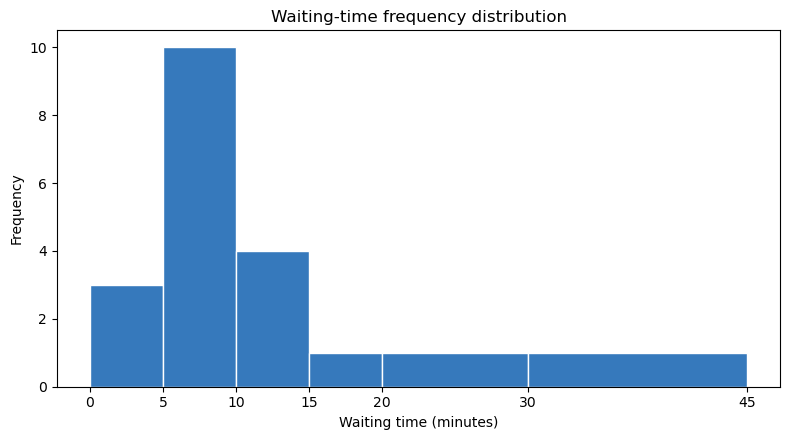

Histogram counts: [3, 10, 4, 1, 1, 1]
pd.cut counts:    [3, 10, 4, 1, 1, 1]
Counts match: True


In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
hist_counts, hist_edges, _ = ax.hist(
    waits, bins=edges, edgecolor="white", color="#3679bc"
)
ax.set_xticks(edges)
ax.set_xlabel("Waiting time (minutes)")
ax.set_ylabel("Frequency")
ax.set_title("Waiting-time frequency distribution")
plt.tight_layout()
plt.show()

print("Histogram counts:", hist_counts.astype(int).tolist())
print("pd.cut counts:   ", bin_counts.tolist())
print("Counts match:", np.array_equal(hist_counts.astype(int), bin_counts.to_numpy()))

## Lab 6 — Changing the bins changes the summary 

**Question:** How sensitive is a histogram to the bin edges?

**Tasks**
1. Group waits into broader intervals `[0, 10)`, `[10, 20)`, and `[20, 45)`.
2. Compare their counts against the original table.
3. Create a second histogram using these broader bin edges.
4. **Interpret:** Which representation makes the 41-minute value easier to notice? What is gained and lost by using broad bins?

Broader bin counts:
wait_min
[0, 10)     13
[10, 20)     5
[20, 45)     2
Name: count, dtype: int64


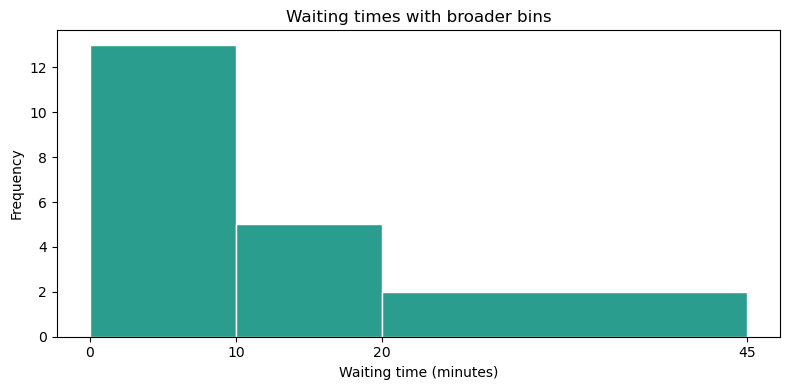

In [7]:
broad_edges = [0, 10, 20, 45]
broad_bins = pd.cut(waits, bins=broad_edges, right=False)
broad_counts = broad_bins.value_counts(sort=False)
print("Broader bin counts:")
print(broad_counts)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(waits, bins=broad_edges, color="#2a9d8f", edgecolor="white")
ax.set_xticks(broad_edges)
ax.set_title("Waiting times with broader bins")
ax.set_xlabel("Waiting time (minutes)")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

## Lab 7 — Interpretation and communication

Write **4–6 sentences** responding to the questions below. Use numerical evidence from your tables and figures.

1. How common are Taxi trips within the observed mode sample?
2. What proportion of the observed waiting times are **10 minutes or less**?
3. Does the waiting-time distribution look symmetric or right-skewed? Why?
4. Why can the mean waiting time alone be misleading?
5. What limitation prevents you from generalizing these samples to the whole city's transportation system?

**Reminder:** These are descriptive conclusions about the observations; they are not population estimates or causal claims.

In [8]:
# Instructor interpretation guide:
# Taxi: 12/30 = 40%; wait <=10: 14/20 = 70%.
# Long tail: 25 and 41 minutes, mean > median.
print("Taxi share:", f"{(modes.eq('Taxi').mean()*100):.1f}%")
print("Wait <= 10:", f"{(waits.le(10).mean()*100):.1f}%")
print("Mean wait:", waits.mean())
print("Median wait:", waits.median())
print("Max wait:", waits.max())

Taxi share: 40.0%
Wait <= 10: 70.0%
Mean wait: 10.45
Median wait: 7.5
Max wait: 41


### Example written interpretation
Taxi is the most frequent mode in the 30-observation mode sample (12/30 = **40%**). In the separate 20-trip waiting-time sample, **70%** of observations are 10 minutes or less. The waiting-time distribution is right-skewed, with a few much longer values (25 and 41 minutes), so the mean exceeds the median. These samples describe the observed records only and do not establish a representative city-wide distribution or any causal explanation.